In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

[codecarbon WARNING @ 12:20:01] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import re


DATA_DIR = Path(
    "data/ecthr_cases_raw"
)

train_raw = pd.read_json(
    DATA_DIR / "train.jsonl",
    lines=True,
)

validation_raw = pd.read_json(
    DATA_DIR / "dev.jsonl",
    lines=True,
)

test_raw = pd.read_json(
    DATA_DIR / "test.jsonl",
    lines=True,
)

train_raw["split"] = "train"
validation_raw["split"] = "validation"
test_raw["split"] = "test"

raw_df = pd.concat(
    [
        train_raw,
        validation_raw,
        test_raw,
    ],
    ignore_index=True,
)

print("Train:", train_raw.shape)
print(
    "Validation:",
    validation_raw.shape,
)
print("Test:", test_raw.shape)
print("Combined:", raw_df.shape)

Train: (9000, 13)
Validation: (1000, 13)
Test: (1000, 13)
Combined: (11000, 13)


In [4]:
def normalize_labels(value):
    if isinstance(
        value,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):
        return sorted({
            str(label)
            for label in value
            if pd.notna(label)
        })

    if pd.isna(value):
        return []

    return [str(value)]


def combine_facts(value):
    if isinstance(
        value,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):
        text = " ".join(
            str(sentence)
            for sentence in value
            if pd.notna(sentence)
        )
    elif pd.isna(value):
        text = ""
    else:
        text = str(value)

    # Preserve punctuation.
    # Only normalize whitespace.
    text = text.replace(
        "\u00a0",
        " ",
    )

    text = re.sub(
        r"\s+",
        " ",
        text,
    )

    return text.strip()

In [5]:
ecthr_df = pd.DataFrame({
    "document_id": (
        raw_df["case_id"]
        .astype(str)
    ),

    "training_text": (
        raw_df["facts"]
        .apply(combine_facts)
    ),

    # Actual 29-label targets
    "target_labels": (
        raw_df[
            "violated_articles"
        ]
        .apply(normalize_labels)
    ),

    "split": (
        raw_df["split"]
        .replace({
            "dev": "validation",
        })
    ),
})

In [6]:
NO_VIOLATION_LABEL = (
    "__NO_VIOLATION__"
)

ecthr_df["labels"] = (
    ecthr_df[
        "target_labels"
    ]
    .apply(
        lambda labels: (
            labels
            if len(labels) > 0
            else [
                NO_VIOLATION_LABEL
            ]
        )
    )
)

In [8]:
ecthr_df = (
    ecthr_df[
        ecthr_df[
            "training_text"
        ]
        .str.len()
        .gt(0)
    ]
    .drop_duplicates(
        subset=[
            "document_id"
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

ecthr_df["char_length"] = (
    ecthr_df[
        "training_text"
    ]
    .str.len()
)

ecthr_df["length"] = (
    ecthr_df[
        "training_text"
    ]
    .str.split()
    .str.len()
)

In [9]:
actual_label_names = sorted(
    ecthr_df[
        "target_labels"
    ]
    .explode()
    .dropna()
    .unique()
)

analysis_label_names = sorted(
    ecthr_df["labels"]
    .explode()
    .dropna()
    .unique()
)

print(
    "Dataset shape:",
    ecthr_df.shape,
)

print(
    "Actual labels:",
    len(actual_label_names),
)

print(actual_label_names)

print(
    "Analysis labels:",
    len(analysis_label_names),
)

print(
    "No-violation documents:",
    ecthr_df[
        "target_labels"
    ]
    .apply(len)
    .eq(0)
    .sum(),
)

print(
    "Minimum word count:",
    ecthr_df["length"].min(),
)

print(
    "Average word count:",
    ecthr_df["length"].mean(),
)

print(
    "Maximum word count:",
    ecthr_df["length"].max(),
)

print("\nSplit counts:")
print(
    ecthr_df[
        "split"
    ].value_counts()
)

display(
    ecthr_df[
        [
            "document_id",
            "training_text",
            "target_labels",
            "labels",
            "split",
            "length",
        ]
    ].head()
)

Dataset shape: (11000, 7)
Actual labels: 29
['10', '11', '12', '13', '14', '18', '2', '3', '34', '38', '4', '46', '5', '6', '7', '8', '9', 'P1-1', 'P1-2', 'P1-3', 'P12-1', 'P4-2', 'P4-4', 'P6-1', 'P6-3', 'P7-1', 'P7-2', 'P7-3', 'P7-4']
Analysis labels: 30
No-violation documents: 1045
Minimum word count: 69
Average word count: 1662.0804545454546
Maximum word count: 35416

Split counts:
split
train         9000
validation    1000
test          1000
Name: count, dtype: int64


,document_id,training_text,target_labels,labels,split,length
0,001-59587,11. At the beginning of the events relevant to...,[8],[8],train,6884
1,001-59591,9. The applicant is the monarch of Liechtenste...,[],[__NO_VIOLATION__],train,2758
2,001-59590,9. In June 1949 plots of agricultural land own...,[6],[6],train,1347
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research work...",[10],[10],train,3859
4,001-59589,"9. The applicant is an Italian citizen, born i...",[],[__NO_VIOLATION__],train,571


In [10]:
sampling_df = (
    ecthr_df[
        ecthr_df["split"]
        == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

In [11]:
display(
    sampling_df[
        [
            "document_id",
            "training_text",
            "labels",
            "length",
        ]
    ].head()
)

,document_id,training_text,labels,length
0,001-59587,11. At the beginning of the events relevant to...,[8],6884
1,001-59591,9. The applicant is the monarch of Liechtenste...,[__NO_VIOLATION__],2758
2,001-59590,9. In June 1949 plots of agricultural land own...,[6],1347
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research work...",[10],3859
4,001-59589,"9. The applicant is an Italian citizen, born i...",[__NO_VIOLATION__],571


In [12]:
TEXT_COL = "training_text"
LABEL_COL = "labels"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]

In [13]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [14]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [15]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [16]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [17]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [18]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [19]:
def prepare_sampling_dataframe(
    training_df,
):
    result = training_df[
        [
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    ].copy()

    # Remove missing essential values
    result = result.dropna(
        subset=[
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    )

    # Remove empty text
    result = result[
        result[TEXT_COL]
        .astype(str)
        .str.strip()
        .ne("")
    ].copy()

    # One row per document
    result = result.drop_duplicates(
        subset=["document_id"],
        keep="first",
    )

    # Character count: descriptive only
    result["char_length"] = (
        result[TEXT_COL]
        .str.len()
    )

    # Word count: used for quantile sampling
    result["length"] = (
        result[TEXT_COL]
        .str.split()
        .str.len()
    )

    result = result.reset_index(
        drop=True
    )

    print(
        "Shape:",
        result.shape,
    )

    print(
        "Minimum word count:",
        result["length"].min(),
    )

    print(
        "Average word count:",
        result["length"].mean(),
    )

    print(
        "Maximum word count:",
        result["length"].max(),
    )

    print(
        "Number of labels:",
        result[LABEL_COL]
        .explode()
        .nunique(),
    )

    return result

In [21]:
sampling_df = (
    prepare_sampling_dataframe(
        sampling_df
    )
)

Shape: (9000, 5)
Minimum word count: 69
Average word count: 1619.237111111111
Maximum word count: 35416
Number of labels: 30


In [22]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    text_col="training_text",
):
    sampling_pool = (
        df.copy()
        .reset_index(drop=True)
    )

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool[text_col]
            .astype(str)
            .str.split()
            .str.len()
        )

    # The actual number of groups cannot exceed:
    # 1. requested quantiles
    # 2. sample size
    # 3. number of unique text lengths
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    # Create length groups from the whole dataset
    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"]
        .nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    sampled_parts = []

    # Sample approximately the same number
    # from every length group
    for group_number, group_df in (
        sampling_pool.groupby(
            "_length_group",
            observed=True,
        )
    ):
        number_to_sample = min(
            samples_per_group,
            len(group_df),
        )

        sampled_part = group_df.sample(
            n=number_to_sample,
            random_state=(
                random_seed
                + int(group_number)
            ),
        )

        sampled_parts.append(
            sampled_part
        )

    sampled_df = pd.concat(
        sampled_parts,
        axis=0,
    )

    # Fill remaining positions if qcut produced
    # fewer groups or some groups were too small
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = (
            sampling_pool.drop(
                index=sampled_df.index
            )
        )

        additional_samples = (
            remaining_pool.sample(
                n=remaining_count,
                random_state=random_seed,
            )
        )

        sampled_df = pd.concat(
            [
                sampled_df,
                additional_samples,
            ],
            axis=0,
        )

    # Shuffle the final sample
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(
            columns=["_length_group"]
        )
        .reset_index(drop=True)
    )

    print(
        "Original dataset size:",
        len(sampling_pool),
    )
    print(
        "Actual sample size:",
        len(sampled_df),
    )
    print(
        "Minimum word count:",
        sampled_df["length"].min(),
    )
    print(
        "Average word count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum word count:",
        sampled_df["length"].max(),
    )
    print(
        "Number of represented labels:",
        sampled_df["labels"]
        .explode()
        .nunique(),
    )

    return sampled_df

In [23]:
sampled_df = sample_from_length_groups(
    df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED,
    text_col=TEXT_COL,
)

Original dataset size: 9000
Actual sample size: 200
Minimum word count: 110
Average word count: 1623.38
Maximum word count: 15510
Number of represented labels: 16


In [24]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [25]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [26]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
            sampled_df["document_id"]
            .tolist()
        ),

        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [27]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                ),
                text_col=text_col,
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [28]:
results = metric_collect(
    grouped_df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

Repetition 1/3
Repetition seed: 383329927
Original dataset size: 9000
Actual sample size: 200
Minimum word count: 80
Average word count: 1656.66
Maximum word count: 21911
Number of represented labels: 16
Actual sample size: 200
Label counts:
labels
10                    7
11                    2
13                   23
14                    5
2                     9
3                    29
34                    3
38                    1
5                    24
6                   103
8                    14
9                     1
P1-1                 34
P1-3                  3
P4-2                  2
__NO_VIOLATION__     20
Name: count, dtype: int64
Number of represented labels: 16

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 6731
Number of label-set pair types: 391
Total unique between-label document pairs: 13169
Same-label target size: 6731
Different-label pair types: 391
Base sample per diff-label pair: 17

Summary:
Same mean: 0.8570003675557302
Different mean: 0.8310999553318967
Mean gap: 0.02590041222383351
Same eta: -0.3691154594124169
Different eta: -0.3390777629306516
Different |eta|: 0.3390777629306516
Eta gap: -0.030037696481765328
Chi-square distance: 0.06808747625791069
Chi-square bootstrap std: 0.0019451470840119278

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (54 outputs left out)

Model: recobo/agriculture-bert-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 5900
Number of label-set pair types: 393
Total unique between-label document pairs: 14000
Same-label target size: 5900
Different-label pair types: 393
Base sample per diff-label pair: 15

Summary:
Same mean: 0.9151779058222044
Different mean: 0.9068188765927492
Mean gap: 0.008359029229455119
Same eta: -0.5147550500321413
Different eta: -0.3015324262071601
Different |eta|: 0.3015324262071601
Eta gap: -0.2132226238249812
Chi-square distance: 0.04165183903333407
Chi-square bootstrap std: 0.0017561405961056035

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 5900
Number of label-set pair types: 393
Total unique between-label document pairs: 14000
Same-label target size: 5900
Different-label pair types: 393
Base sample per diff-label pair: 15

Summary:
Same mean: 0.9431728854118767
Different mean: 0.9446595391386444
Mean gap: -0.001486653726767711
Same eta: -0.657097173466438
Different eta: -0.5929286651945203
Different |eta|: 0.5929286651945203
Eta gap: -0.06416850827191783
Chi-square distance: 0.01996982217804242
Chi-square bootstrap std: 0.0012585634287083291


In [29]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.857000,-0.369115,0.369115,6731,0.831100,0.000399,-0.339078,0.014667,0.339078,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
1,allenai/scibert_scivocab_uncased,0.897407,-0.361562,0.361562,6731,0.886645,0.000239,-0.476068,0.012258,0.476068,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
2,nlpaueb/legal-bert-base-uncased,0.894282,-0.405561,0.405561,6731,0.881646,0.000258,-0.260455,0.015497,0.260455,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
3,ahmedrachid/FinancialBERT,0.899092,-0.324428,0.324428,6731,0.891600,0.000253,-0.383925,0.012726,0.383925,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
4,Lianglab/PharmBERT-uncased,0.872727,-0.409054,0.409054,6731,0.857553,0.000317,-0.411213,0.010646,0.411213,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
5,recobo/agriculture-bert-uncased,0.917878,-0.369299,0.369299,6731,0.907254,0.000195,-0.436875,0.012415,0.436875,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
6,recobo/chemical-bert-uncased,0.945241,-0.552332,0.552332,6731,0.927419,0.000223,-0.631703,0.010473,0.631703,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,16
7,google-bert/bert-base-uncased,0.857914,-0.392119,0.392119,7013,0.851757,0.000328,-0.222799,0.013042,0.222799,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,16
8,allenai/scibert_scivocab_uncased,0.894773,-0.491265,0.491265,7013,0.892561,0.000282,-0.297825,0.014547,0.297825,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,16
9,nlpaueb/legal-bert-base-uncased,0.885032,-0.453776,0.453776,7013,0.884067,0.000285,-0.388113,0.013023,0.388113,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,16


In [30]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.871859,0.005378,0.860020,0.004919,0.000314,-0.446193,0.063977,0.446193,0.063977,...,0.012332,0.126016,0.102850,0.047186,0.005902,0.001783,6548.0,6548.0,15.666667,3
1,ahmedrachid/FinancialBERT,0.897774,0.001179,0.889207,0.005099,0.000284,-0.399436,0.066224,0.399436,0.066224,...,0.011693,0.054989,0.041467,0.023276,0.008566,0.001269,6548.0,6548.0,15.666667,3
2,allenai/scibert_scivocab_uncased,0.895659,0.001514,0.888706,0.003341,0.000258,-0.454865,0.081450,0.454865,0.081450,...,0.013691,0.161392,0.041506,0.032564,0.000887,0.001369,6548.0,6548.0,15.666667,3
3,google-bert/bert-base-uncased,0.855818,0.002875,0.842371,0.010457,0.000366,-0.404915,0.043628,0.404915,0.043628,...,0.014379,0.125956,0.083031,0.050605,0.017168,0.001841,6548.0,6548.0,15.666667,3
4,nlpaueb/legal-bert-base-uncased,0.891294,0.005425,0.883482,0.001625,0.000277,-0.421211,0.028209,0.421211,0.028209,...,0.014079,0.126694,0.054222,0.022935,0.012354,0.001223,6548.0,6548.0,15.666667,3
5,recobo/agriculture-bert-uncased,0.916504,0.001351,0.909450,0.004186,0.000214,-0.448214,0.073513,0.448214,0.073513,...,0.014100,0.165274,0.084614,0.030792,0.011401,0.001368,6548.0,6548.0,15.666667,3
6,recobo/chemical-bert-uncased,0.944739,0.001386,0.939461,0.010461,0.000191,-0.624479,0.062577,0.624479,0.062577,...,0.012166,0.131437,0.103626,0.027415,0.006468,0.001292,6548.0,6548.0,15.666667,3


In [31]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,2,2,4,5,5,2
1,ahmedrachid/FinancialBERT,3,5,3,3,7,2,7,6
2,allenai/scibert_scivocab_uncased,4,4,6,6,2,3,2,3
3,google-bert/bert-base-uncased,7,1,1,1,6,7,6,1
4,nlpaueb/legal-bert-base-uncased,5,3,4,4,5,6,4,7
5,recobo/agriculture-bert-uncased,2,6,5,5,3,4,1,4
6,recobo/chemical-bert-uncased,1,7,7,7,1,1,3,5


In [32]:
real_rank_map = {
    "allenai/scibert_scivocab_uncased": 1,
    "recobo/agriculture-bert-uncased": 2,
    "nlpaueb/legal-bert-base-uncased": 3,
    "ahmedrachid/FinancialBERT": 4,
    "Lianglab/PharmBERT-uncased": 5,
    "recobo/chemical-bert-uncased": 6,
    "google-bert/bert-base-uncased": 7,
}

# Select models spanning the real ranking
selected_real_ranks = [
    1,
    2,
    4,
    6,
    7,
]

selected_models = [
    model_name
    for model_name, real_rank
    in real_rank_map.items()
    if real_rank in selected_real_ranks
]

# Sort from best to worst
selected_models = sorted(
    selected_models,
    key=lambda model_name:
        real_rank_map[model_name],
)

print("Selected models:")

for model_name in selected_models:
    print(
        f"Rank {real_rank_map[model_name]}: "
        f"{model_name}"
    )

Selected models:
Rank 1: allenai/scibert_scivocab_uncased
Rank 2: recobo/agriculture-bert-uncased
Rank 4: ahmedrachid/FinancialBERT
Rank 6: recobo/chemical-bert-uncased
Rank 7: google-bert/bert-base-uncased


In [33]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, 4):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [34]:
for model_name, values in (
    distribution_data.items()
):
    print(
        model_name,
        "| rank:",
        values["real_rank"],
        "| same:",
        len(values["same_scores"]),
        "| different:",
        len(values["diff_scores"]),
    )

allenai/scibert_scivocab_uncased | rank: 1 | same: 19644 | different: 40056
recobo/agriculture-bert-uncased | rank: 2 | same: 19644 | different: 40056
ahmedrachid/FinancialBERT | rank: 4 | same: 19644 | different: 40056
recobo/chemical-bert-uncased | rank: 6 | same: 19644 | different: 40056
google-bert/bert-base-uncased | rank: 7 | same: 19644 | different: 40056


In [35]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1 gets the darkest red.
    # Rank 7 remains light but visible.
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Reds(
            colour_position
        )
    )

In [36]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.6410606557130814 0.9869926751852035


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

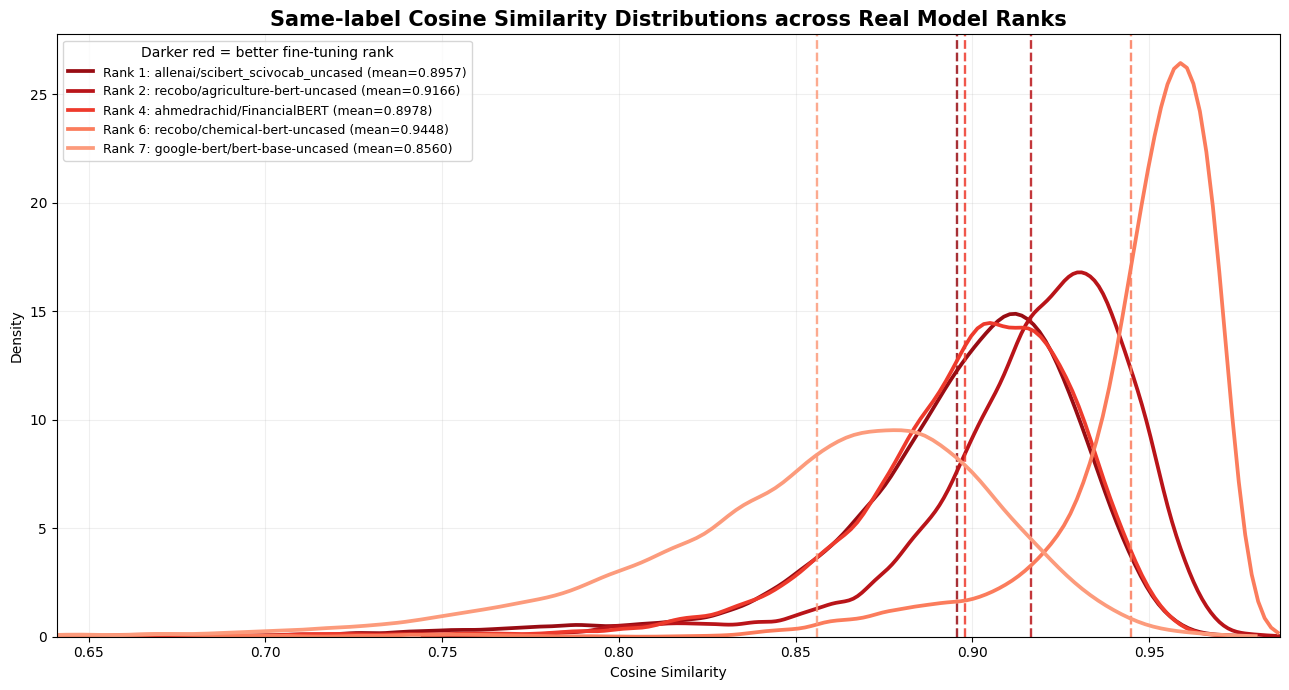

In [41]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "ohsumed_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

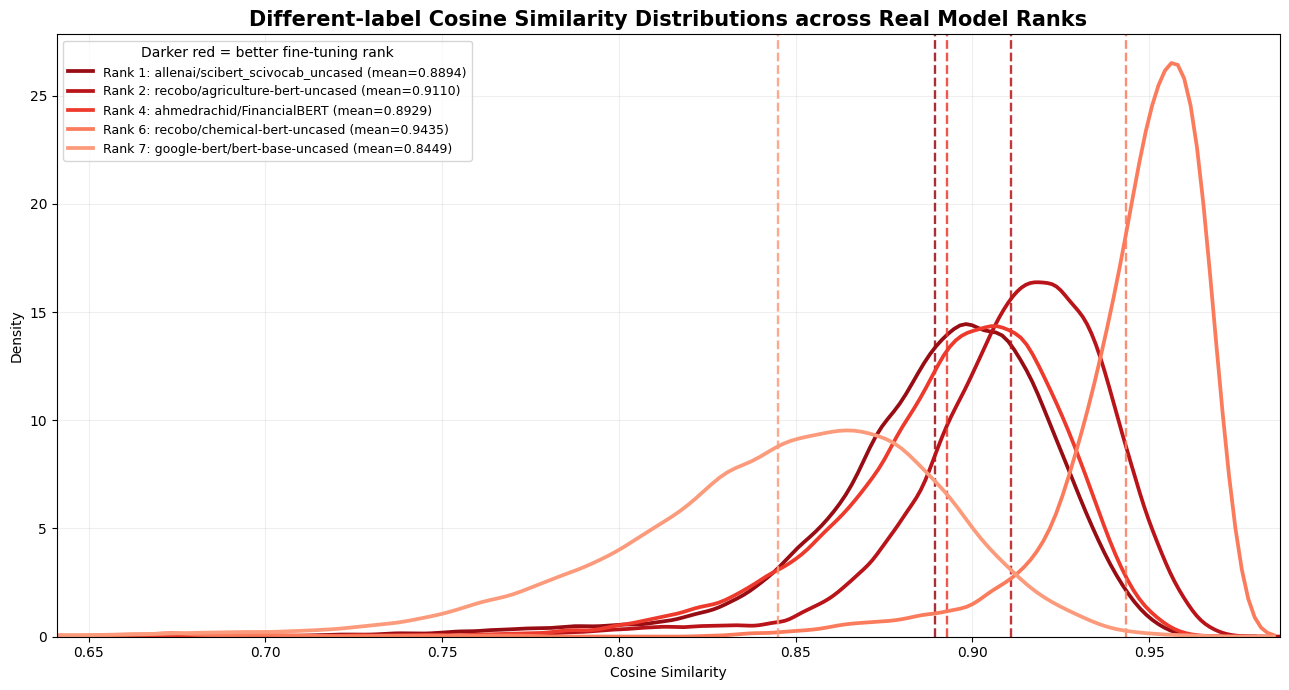

In [43]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        "ohsumed_different_label_"
        "rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()